# Assignment 7

In [ ]:
# show all ouputs in a cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [ ]:
# import libraries
import numpy as np
from sklearn import datasets
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.svm import SVC
from sklearn.svm import SVR
from sklearn.linear_model import SGDClassifier
from sklearn.datasets import make_moons
from sklearn.preprocessing import PolynomialFeatures
import matplotlib.pyplot as plt
from mlxtend.plotting import plot_decision_regions
import matplotlib.gridspec as gridspec
from sklearn.svm import LinearSVR
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import plot_tree
from sklearn.tree import export_graphviz
import graphviz
import pandas as pd
import kagglehub

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.tree import plot_tree, export_text

from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.ensemble import ExtraTreesClassifier

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
import xgboost
from sklearn.ensemble import StackingClassifier

## Task I

This assignment will use the following dataset from Kaggle. The dataset can be downloaded from: https://www.kaggle.com/houcembenmansour/predict-diabetes-based-on-diagnostic-measures?select=diabetes.csv

This dataset is originally from the National Institute of Diabetes and Digestive and Kidney Diseases. The objective of the dataset is to diagnostically predict whether or not a patient has diabetes based on specific diagnostic measurements included in the dataset. The dataset consists of several medical predictor variables and one target variable for diabetes. Predictor variables include the number of pregnancies the patient has had, their body mass index (BMI), weight, age, glucose, and so on.

**Features to be used in the model:**
- cholesterol
- glucose
- hdl_chol
- chol_hdl_ratio
- age
- gender
- bmi
- systolic_bp
- diastolic_bp
- waist
- waist_hip_ratio

**Target to be used in the model:**
- diabetes (Diabetes, No diabetes)

Use Colab for the following programming questions.

### Task I, Question 1

Read the data into Google Colab using .read_csv() function. Note that you may need to use “decimal = ","” argument in .read_csv() function because a comma separates the decimal points and the digits in the dataset.

In [ ]:
path = kagglehub.dataset_download("houcembenmansour/predict-diabetes-based-on-diagnostic-measures")

print("Path to dataset files:", path)

100%|██████████| 8.88k/8.88k [00:00<00:00, 13.1MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/houcembenmansour/predict-diabetes-based-on-diagnostic-measures/versions/1


In [ ]:
data = pd.read_csv(path + '/diabetes.csv', decimal = ",")

### Task I, Question 2

For simplicity, remove the features not listed above from the dataframe.

In [ ]:
columns_to_keep = [
    'cholesterol', 'glucose', 'hdl_chol', 'chol_hdl_ratio',
    'age', 'gender', 'bmi', 'systolic_bp', 'diastolic_bp',
    'waist', 'waist_hip_ratio', 'diabetes'
]

data2 = data[columns_to_keep].copy()
data2.columns

Index(['cholesterol', 'glucose', 'hdl_chol', 'chol_hdl_ratio', 'age', 'gender',
       'bmi', 'systolic_bp', 'diastolic_bp', 'waist', 'waist_hip_ratio',
       'diabetes'],
      dtype='object')

### Task I, Question 3

Print the first and last five rows of the dataframe using .head() and .tail() functions. How many observations (i.e., sample size) do you have in total?

In [ ]:
data2.head()
print("\n")
data2.tail()
print("\n")
print("Number of observations:", data2.shape[0])

,cholesterol,glucose,hdl_chol,chol_hdl_ratio,age,gender,bmi,systolic_bp,diastolic_bp,waist,waist_hip_ratio,diabetes
0,193,77,49,3.9,19,female,22.5,118,70,32,0.84,No diabetes
1,146,79,41,3.6,19,female,26.4,108,58,33,0.83,No diabetes
2,217,75,54,4.0,20,female,29.3,110,72,40,0.89,No diabetes
3,226,97,70,3.2,20,female,19.6,122,64,31,0.79,No diabetes
4,164,91,67,2.4,20,female,20.2,122,86,32,0.82,No diabetes


,cholesterol,glucose,hdl_chol,chol_hdl_ratio,age,gender,bmi,systolic_bp,diastolic_bp,waist,waist_hip_ratio,diabetes
385,227,105,44,5.2,83,female,25.2,150,90,35,0.88,No diabetes
386,226,279,52,4.3,84,female,37.5,144,88,41,0.85,Diabetes
387,301,90,118,2.6,89,female,21.7,218,90,31,0.76,No diabetes
388,232,184,114,2.0,91,female,24.0,170,82,35,0.92,Diabetes
389,165,94,69,2.4,92,female,39.7,160,82,51,1.00,No diabetes




Number of observations: 390


### Task I, Question 4

Use .info() to get a short description of the dataframe.

In [ ]:
data2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 390 entries, 0 to 389
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   cholesterol      390 non-null    int64  
 1   glucose          390 non-null    int64  
 2   hdl_chol         390 non-null    int64  
 3   chol_hdl_ratio   390 non-null    float64
 4   age              390 non-null    int64  
 5   gender           390 non-null    object 
 6   bmi              390 non-null    float64
 7   systolic_bp      390 non-null    int64  
 8   diastolic_bp     390 non-null    int64  
 9   waist            390 non-null    int64  
 10  waist_hip_ratio  390 non-null    float64
 11  diabetes         390 non-null    object 
dtypes: float64(3), int64(7), object(2)
memory usage: 36.7+ KB


### Task I, Question 5

Take a look at the target (i.e., diabetes) using .value_counts() function. What is the prevalence of diabetes in the dataframe?

In [ ]:
data2['diabetes'].value_counts()

,count
diabetes,
No diabetes,330
Diabetes,60


In [ ]:
diabetes_pct = data2['diabetes'].value_counts()['Diabetes'] / len(data2) * 100
print("prevalence of diabetes in the dataframe:", diabetes_pct, "%")

prevalence of diabetes in the dataframe: 15.384615384615385 %


### Task I, Question 6

Take a look at the only categorical feature (i.e., gender) using .value_counts() function. What is the prevalence of females in the dataframe?

In [ ]:
data2['gender'].value_counts()

,count
gender,
female,228
male,162


In [ ]:
female_pct = data2['gender'].value_counts()['female'] / len(data2) * 100
print("prevalence of females in the dataframe:", female_pct, "%")

prevalence of females in the dataframe: 58.46153846153847 %


### Task I, Question 7

Report the descriptive statistics of the numerical features using .describe() function.

In [ ]:
data2.describe()

,cholesterol,glucose,hdl_chol,chol_hdl_ratio,age,bmi,systolic_bp,diastolic_bp,waist,waist_hip_ratio
count,390.000000,390.000000,390.000000,390.000000,390.000000,390.000000,390.000000,390.000000,390.000000,390.000000
mean,207.230769,107.338462,50.266667,4.524615,46.774359,28.775641,137.133333,83.289744,37.869231,0.881385
std,44.666005,53.798188,17.279069,1.736634,16.435911,6.600915,22.859528,13.498192,5.760947,0.073212
min,78.000000,48.000000,12.000000,1.500000,19.000000,15.200000,90.000000,48.000000,26.000000,0.680000
25%,179.000000,81.000000,38.000000,3.200000,34.000000,24.100000,122.000000,75.000000,33.000000,0.830000
50%,203.000000,90.000000,46.000000,4.200000,44.500000,27.800000,136.000000,82.000000,37.000000,0.880000
75%,229.000000,107.750000,59.000000,5.400000,60.000000,32.275000,148.000000,90.000000,41.000000,0.930000
max,443.000000,385.000000,120.000000,19.300000,92.000000,55.800000,250.000000,124.000000,56.000000,1.140000


### Task I, Question 8

Create a pipeline to process numeric features using .Pipeline() function. In the pipeline, include the following two processes: first, replace missing values of a feature with its median; and second, standardize the feature.

In [ ]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("std_scaler", StandardScaler())
])

### Task I, Question 9

Create a full pipeline to process both numerical and categorical features using .ColumnTransformer() function. Use .OneHotEncoder() function to one hot encode the the categorical feasure (i.e., gender).

In [ ]:
num_features = [
    'cholesterol', 'glucose', 'hdl_chol', 'chol_hdl_ratio',
    'age', 'bmi', 'systolic_bp', 'diastolic_bp',
    'waist', 'waist_hip_ratio'
]
cat_features = ['gender']

full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)
])

### Task I, Question 10

Separate the target from the features and make them two separate NumPy arrays. Then split the dataframe into train and test sets. Include 20% of the data in the test set.

In [ ]:
# Separate the target from the features
y = np.c_[data2["diabetes"]]
X = data2.drop("diabetes", axis=1)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

# Place 20% of observations in the test set
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

Feature shape: (390, 11)
Target shape: (390, 1)


### Task I, Question 11

Fit and transform the train set using the full pipeline.

In [ ]:
X_train_prepared = full_pipeline.fit_transform(X_train)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_prepared.shape)

Original training shape: (312, 11)
Processed training shape: (312, 12)


### Task I, Question 12

Transform the test set using the full pipeline.

In [ ]:
X_test_prepared = full_pipeline.transform(X_test)

### Task I, Question 13

Fit a linear Support Vector Classification (SVC) model on the train set. (Hint: use . LinearSVC() function or .SVC(kernel = 'linear') function). Calculate the accuracy of the model based on the test set.

In [ ]:
linear_svc = SVC(kernel='linear', C=1)
linear_svc.fit(X_train_prepared, y_train.ravel())

y_pred_linear = linear_svc.predict(X_test_prepared)
linear_accuracy = accuracy_score(y_test.ravel(), y_pred_linear)

print('Linear SVC test accuracy:', linear_accuracy)

SVC(C=1, kernel='linear')

Linear SVC test accuracy: 0.9102564102564102


### Task I, Question 14

Fit a nonlinear SVC model on the train set using a polynomial kernel. Calculate the accuracy of the model based on the test set.

In [ ]:
poly_svc = SVC(kernel='poly', degree=3, coef0=1, C=5)
poly_svc.fit(X_train_prepared, y_train.ravel())

y_pred_poly = poly_svc.predict(X_test_prepared)
poly_accuracy = accuracy_score(y_test.ravel(), y_pred_poly)

print('Polynomial SVC test accuracy:', poly_accuracy)

SVC(C=5, coef0=1, kernel='poly')

Polynomial SVC test accuracy: 0.8589743589743589


### Task I, Question 15

Fit a nonlinear SVC model on the train set using a radial basis function (RBF) kernel. Calculate the accuracy of the model based on the test set.

In [ ]:
rbf_svc = SVC(kernel='rbf')
rbf_svc.fit(X_train_prepared, y_train.ravel())

y_pred_rbf = rbf_svc.predict(X_test_prepared)
rbf_accuracy = accuracy_score(y_test.ravel(), y_pred_rbf)

print('RBF SVC test accuracy:', rbf_accuracy)

SVC()

RBF SVC test accuracy: 0.8717948717948718


### Task I, Question 16

Compare the three accuracies based on the linear SVC and the two nonlinear SVC models. Which model achieves the highest accuracy based on the test set?

The linear SVC model achieves the highest accuracy based on the test set.

### Task I, Question 17

Train a decision tree classifier using max_depth = 2 on the train set.

In [ ]:
tree_clf = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf.fit(X_train_prepared, y_train.ravel())

DecisionTreeClassifier(max_depth=2, random_state=42)

### Task I, Question 18

Use either sklearn.tree.plot_tree() or export_graphviz() function to plot the above decision tree. Explain the decision-making rules of the decision tree for all branches.

<Figure size 1600x800 with 0 Axes>

[Text(0.5, 0.8333333333333334, 'num__glucose <= 1.091\ngini = 0.242\nsamples = 312\nvalue = [44, 268]\nclass = No diabetes'),
 Text(0.25, 0.5, 'num__glucose <= 0.033\ngini = 0.113\nsamples = 282\nvalue = [17, 265]\nclass = No diabetes'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'gini = 0.033\nsamples = 235\nvalue = [4, 231]\nclass = No diabetes'),
 Text(0.375, 0.16666666666666666, 'gini = 0.4\nsamples = 47\nvalue = [13, 34]\nclass = No diabetes'),
 Text(0.75, 0.5, 'num__hdl_chol <= -1.809\ngini = 0.18\nsamples = 30\nvalue = [27, 3]\nclass = Diabetes'),
 Text(0.625, 0.6666666666666667, '  False'),
 Text(0.625, 0.16666666666666666, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]\nclass = No diabetes'),
 Text(0.875, 0.16666666666666666, 'gini = 0.128\nsamples = 29\nvalue = [27, 2]\nclass = Diabetes')]

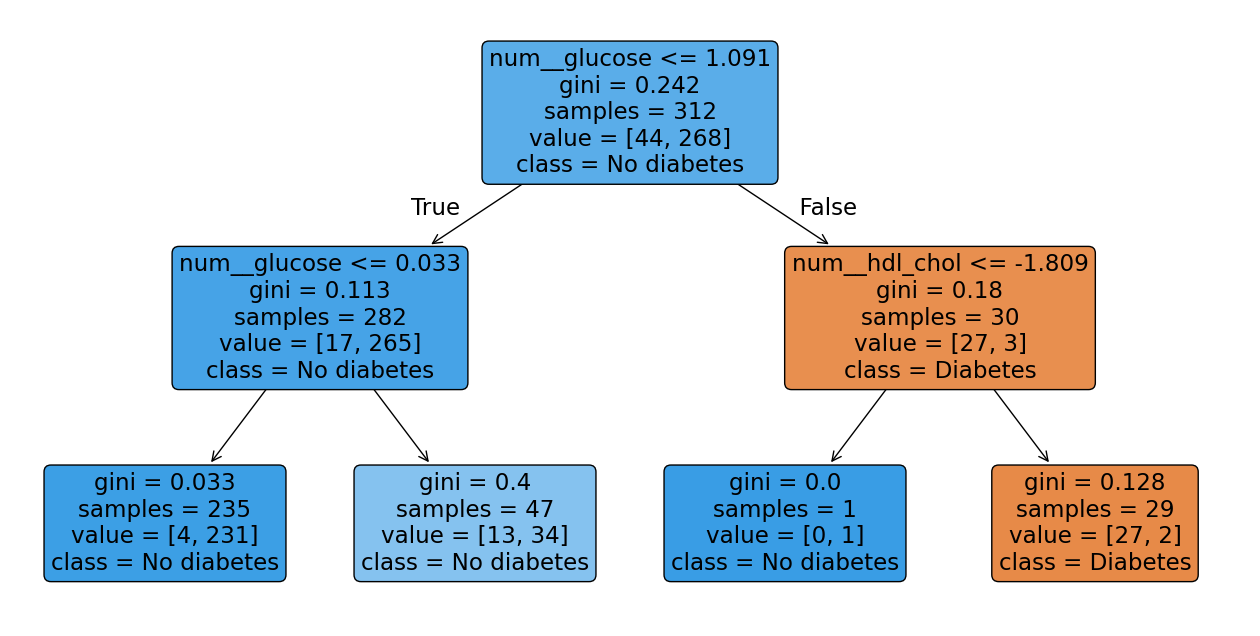

|--- num__glucose <= 1.09
|   |--- num__glucose <= 0.03
|   |   |--- class: No diabetes
|   |--- num__glucose >  0.03
|   |   |--- class: No diabetes
|--- num__glucose >  1.09
|   |--- num__hdl_chol <= -1.81
|   |   |--- class: No diabetes
|   |--- num__hdl_chol >  -1.81
|   |   |--- class: Diabetes



In [ ]:
feature_names = full_pipeline.get_feature_names_out()

plt.figure(figsize=(16, 8))
plot_tree(
    tree_clf,
    feature_names=feature_names,
    class_names=[str(value) for value in tree_clf.classes_],
    filled=True,
    rounded=True
)
plt.show()

print(export_text(tree_clf, feature_names=list(feature_names)))

If standardized glucose is at or below 0.033, the tree predicts No diabetes; if it is above 0.033 but at or below 1.091, it also predicts No diabetes. For glucose above 1.091, standardized HDL cholesterol at or below −1.809 predicts No diabetes, while HDL above −1.809 predicts Diabetes.

## Task II

This assignment will use the following dataset from Kaggle. The dataset can be downloaded from: https://www.kaggle.com/dileep070/heart-disease-prediction-using-logistic-regression

The dataset is from an ongoing cardiovascular study on residents of the town of Framingham, Massachusetts. The classification goal is to predict whether the patient has a 10-year risk of future coronary heart disease (CHD). The dataset provides the patients’ information. It includes over 4,000 records and 15 attributes.

**Features to be used in the model:**

• male: whether or not the patient is a male

• age: age of the patient

• currentSmoker: whether or not the patient is a current smoker

• cigsPerDay: the number of cigarettes that the person smoked on average in one day

• BPMeds: whether or not the patient was on blood pressure medication

• prevalentStroke: whether or not the patient had previously had a stroke

• prevalentHyp: whether or not the patient was hypertensive

• diabetes: whether or not the patient had diabetes

• totChol: total cholesterol level

• sysBP: systolic blood pressure

• diaBP: diastolic blood pressure

• BMI: body mass index

• heartRate: heart rate

• glucose: glucose level

**Target:**

• TenYearCHD: 10-year risk of coronary heart disease (CHD) (1 = “yes” and 0 = “No”)

Use Colab for the following programming questions.


### Task II, Question 1

Read the data into Google Colab using .read_csv() function.

In [ ]:
# Download latest version
path = kagglehub.dataset_download("dileep070/heart-disease-prediction-using-logistic-regression")

print("Path to dataset files:", path)

100%|██████████| 58.4k/58.4k [00:00<00:00, 18.8MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/dileep070/heart-disease-prediction-using-logistic-regression/versions/1


In [ ]:
framingham_dat = pd.read_csv(path + '/framingham.csv', decimal = ",")

### Task II, Question 2

For simplicity, remove the features not listed above from the dataframe.

In [ ]:
columns_to_keep = [
    'male', 'age', 'currentSmoker', 'cigsPerDay', 'BPMeds',
    'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol',
    'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD'
]

framingham_dat = framingham_dat[columns_to_keep].copy()
framingham_dat.columns

Index(['male', 'age', 'currentSmoker', 'cigsPerDay', 'BPMeds',
       'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP',
       'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD'],
      dtype='object')

### Task II, Question 3

Print the first and last five rows of the dataframe using .head() and .tail() functions. How many observations (i.e., sample size) do you have in total?

In [ ]:
framingham_dat.head()
print("\n")
framingham_dat.tail()
print("\n")
print("Number of observations:", framingham_dat.shape[0])

,male,age,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,0,0.0,0.0,0,0,0,195.0,106,70,26.97,80.0,77.0,0
1,0,46,0,0.0,0.0,0,0,0,250.0,121,81,28.73,95.0,76.0,0
2,1,48,1,20.0,0.0,0,0,0,245.0,127.5,80,25.34,75.0,70.0,0
3,0,61,1,30.0,0.0,0,1,0,225.0,150,95,28.58,65.0,103.0,1
4,0,46,1,23.0,0.0,0,0,0,285.0,130,84,23.1,85.0,85.0,0


,male,age,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
4233,1,50,1,1.0,0.0,0,1,0,313.0,179,92,25.97,66.0,86.0,1
4234,1,51,1,43.0,0.0,0,0,0,207.0,126.5,80,19.71,65.0,68.0,0
4235,0,48,1,20.0,NaN,0,0,0,248.0,131,72,22,84.0,86.0,0
4236,0,44,1,15.0,0.0,0,0,0,210.0,126.5,87,19.16,86.0,NaN,0
4237,0,52,0,0.0,0.0,0,0,0,269.0,133.5,83,21.47,80.0,107.0,0




Number of observations: 4238


### Task II, Question 4

Use .info() to get a short description of the dataframe.

In [ ]:
framingham_dat.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   currentSmoker    4238 non-null   int64  
 3   cigsPerDay       4209 non-null   float64
 4   BPMeds           4185 non-null   float64
 5   prevalentStroke  4238 non-null   int64  
 6   prevalentHyp     4238 non-null   int64  
 7   diabetes         4238 non-null   int64  
 8   totChol          4188 non-null   float64
 9   sysBP            4238 non-null   object 
 10  diaBP            4238 non-null   object 
 11  BMI              4219 non-null   object 
 12  heartRate        4237 non-null   float64
 13  glucose          3850 non-null   float64
 14  TenYearCHD       4238 non-null   int64  
dtypes: float64(5), int64(7), object(3)
memory usage: 496.8+ KB


### Task II, Question 5

Pay attention to the variable description. Do Pandas read the variable types correctly (namely, male, currentSmoke, BPMeds, prevalentStroke, prevalentHyp, diabetes, and TenYearCHD should be categorical variables, whereas the others should be numerical variables)? If not, change them to their corresponding data types. (Hint: to convert a numerical feature to a categorical feature, you may consult with the following example code).

In [ ]:
# Convert numerical columns that were read as objects
framingham_dat['sysBP'] = pd.to_numeric(framingham_dat.sysBP.astype('string').str.replace(',', '.', regex=False))
framingham_dat['diaBP'] = pd.to_numeric(framingham_dat.diaBP.astype('string').str.replace(',', '.', regex=False))
framingham_dat['BMI'] = pd.to_numeric(framingham_dat.BMI.astype('string').str.replace(',', '.', regex=False))

# Convert indicator columns and the target to categorical
framingham_dat['male'] = pd.Categorical(framingham_dat.male)
framingham_dat['currentSmoker'] = pd.Categorical(framingham_dat.currentSmoker)
framingham_dat['BPMeds'] = pd.Categorical(framingham_dat.BPMeds)
framingham_dat['prevalentStroke'] = pd.Categorical(framingham_dat.prevalentStroke)
framingham_dat['prevalentHyp'] = pd.Categorical(framingham_dat.prevalentHyp)
framingham_dat['diabetes'] = pd.Categorical(framingham_dat.diabetes)
framingham_dat['TenYearCHD'] = pd.Categorical(framingham_dat.TenYearCHD)

framingham_dat.dtypes

,0
male,category
age,int64
currentSmoker,category
cigsPerDay,float64
BPMeds,category
prevalentStroke,category
prevalentHyp,category
diabetes,category
totChol,float64
sysBP,Float64


### Task II, Question 6

Take a look at the target (i.e., TenYearCHD) using .value_counts() function. What is the 10-year incidence rate of CHD in the dataframe?

In [ ]:
framingham_dat['TenYearCHD'].value_counts()

,count
TenYearCHD,
0,3594
1,644


In [ ]:
chd_pct = framingham_dat['TenYearCHD'].value_counts()[1] / len(framingham_dat) * 100
print("prevalence of the 10-year incidence rate of CHD in the dataframe:", chd_pct, "%")

prevalence of the 10-year incidence rate of CHD in the dataframe: 15.19584709768759 %


### Task II, Question 7

Report the descriptive statistics of the numerical features using .describe() function.

In [ ]:
framingham_dat.describe()

,age,cigsPerDay,totChol,sysBP,diaBP,BMI,heartRate,glucose
count,4238.000000,4209.000000,4188.000000,4238.0,4238.0,4219.0,4237.000000,3850.000000
mean,49.584946,9.003089,236.721585,132.352407,82.893464,25.802008,75.878924,81.966753
std,8.572160,11.920094,44.590334,22.038097,11.91085,4.080111,12.026596,23.959998
min,32.000000,0.000000,107.000000,83.5,48.0,15.54,44.000000,40.000000
25%,42.000000,0.000000,206.000000,117.0,75.0,23.07,68.000000,71.000000
50%,49.000000,0.000000,234.000000,128.0,82.0,25.4,75.000000,78.000000
75%,56.000000,20.000000,263.000000,144.0,89.875,28.04,83.000000,87.000000
max,70.000000,70.000000,696.000000,295.0,142.5,56.8,143.000000,394.000000


### Task II, Question 8

Report the descriptive statistics of the categorical features using .value_counts() function.

In [ ]:
categorical_features = [
    'male', 'currentSmoker', 'BPMeds',
    'prevalentStroke', 'prevalentHyp', 'diabetes'
]

for feature in categorical_features:
    print('\n')
    print(framingham_dat[feature].value_counts(dropna=False))



male
0    2419
1    1819
Name: count, dtype: int64


currentSmoker
0    2144
1    2094
Name: count, dtype: int64


BPMeds
 0.0    4061
 1.0     124
NaN       53
Name: count, dtype: int64


prevalentStroke
0    4213
1      25
Name: count, dtype: int64


prevalentHyp
0    2922
1    1316
Name: count, dtype: int64


diabetes
0    4129
1     109
Name: count, dtype: int64


### Task II, Question 9

Create a pipeline to process numerical features using .Pipeline() function. In the pipeline, include the following two processes: first, replace missing values of a feature with its median; and second, standardize the feature.

In [ ]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("std_scaler", StandardScaler())
])

### Task II, Question 10

Create a full pipeline to process both numerical and categorical features using .ColumnTransformer() function. Use .OneHotEncoder() function to one hot encode the categorical feasures.

In [ ]:
num_features = ['age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']

full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

### Task II, Question 11

Separate the target from the features and make them two separate NumPy arrays. Then split the dataframe into train and test sets. Include 20% of the data in the test set.

In [ ]:
# Separate the target from the features
y = np.c_[framingham_dat["TenYearCHD"]]
X = framingham_dat.drop("TenYearCHD", axis=1)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

# Place 20% of observations in the test set
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

Feature shape: (4238, 14)
Target shape: (4238, 1)


### Task II, Question 12

Fit and transform the train set using the full pipeline.

In [ ]:
X_train_prepared = full_pipeline.fit_transform(X_train)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_prepared.shape)

Original training shape: (3390, 14)
Processed training shape: (3390, 21)


### Task II, Question 13

Transform the test set using the full pipeline.

In [ ]:
X_test_prepared = full_pipeline.transform(X_test)

### Task II, Question 14

Build and train a voting classifier consisting of three different classifiers on the train set: logistic regression, random-forest classifier, and linear Support Vector Machine (SVC) classifier.

In [ ]:
log_clf = LogisticRegression(max_iter=1000)
rnd_clf = RandomForestClassifier(random_state=42)
svm_clf = SVC(kernel='linear', C=1)

voting_clf = VotingClassifier(
    estimators=[('lr', log_clf), ('rf', rnd_clf), ('svc', svm_clf)],
    voting='hard'
)

voting_clf.fit(X_train_prepared, y_train.ravel())

VotingClassifier(estimators=[('lr', LogisticRegression(max_iter=1000)),
                             ('rf', RandomForestClassifier(random_state=42)),
                             ('svc', SVC(C=1, kernel='linear'))])

### Task II, Question 15

Calculate the accuracy of each separate classifier (i.e., logistic regression, random-forest classifier, and linear SVC) as well as the voting classifier on the test set. Does the voting classifier perform better than the three classifiers (i.e., logistic regression, random-forest classifier, and linear SVC classifier)?

In [ ]:
log_clf.fit(X_train_prepared, y_train.ravel())
log_accuracy = accuracy_score(y_test.ravel(), log_clf.predict(X_test_prepared))
print('Logistic regression:', log_accuracy)

rnd_clf.fit(X_train_prepared, y_train.ravel())
rf_accuracy = accuracy_score(y_test.ravel(), rnd_clf.predict(X_test_prepared))
print('\nRandom forest:', rf_accuracy)

svm_clf.fit(X_train_prepared, y_train.ravel())
svm_accuracy = accuracy_score(y_test.ravel(), svm_clf.predict(X_test_prepared))
print('\nLinear SVC:', svm_accuracy)

voting_accuracy = accuracy_score(y_test.ravel(), voting_clf.predict(X_test_prepared))
print('\nVoting classifier:', voting_accuracy)

LogisticRegression(max_iter=1000)

Logistic regression: 0.8573113207547169


RandomForestClassifier(random_state=42)


Random forest: 0.8525943396226415


SVC(C=1, kernel='linear')


Linear SVC: 0.8537735849056604

Voting classifier: 0.8584905660377359


Among the 3 individual classifiers, logistic regression has the highest accuracy (85.7%); the voting classifier perform slightly better than all the individual classifiers, having an accuracy of 85.8%.

### Task II, Question 16

Fit an Extremely Randomized Trees (Extra-Trees) classifier on the train set. Calculate the accuracy based on the test set.

In [ ]:
extra_clf = ExtraTreesClassifier(random_state=42)
extra_clf.fit(X_train_prepared, y_train.ravel())

extra_pred = extra_clf.predict(X_test_prepared)
extra_accuracy = accuracy_score(y_test.ravel(), extra_pred)

print('Extra Trees test accuracy:', extra_accuracy)

ExtraTreesClassifier(random_state=42)

Extra Trees test accuracy: 0.8514150943396226


### Task II, Question 17

Fit an AdaBoost classifier on the train set. Calculate the accuracy based on the test set.

In [ ]:
ada_clf = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=200, learning_rate=0.5)

ada_clf.fit(X_train_prepared, y_train.ravel())
ada_pred = ada_clf.predict(X_test_prepared)
ada_accuracy = accuracy_score(y_test.ravel(), ada_pred)

print('AdaBoost test accuracy:', ada_accuracy)

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                   learning_rate=0.5, n_estimators=200)

AdaBoost test accuracy: 0.8537735849056604


### Task II, Question 18

Fit a Gradient Boosting classifier on the train set. Calculate the accuracy base on the test set.

In [ ]:
gbrt_clf = GradientBoostingClassifier(
    max_depth=5,
    n_estimators=100,
    learning_rate=0.3
)

gbrt_clf.fit(X_train_prepared, y_train.ravel())
gbrt_pred = gbrt_clf.predict(X_test_prepared)
gbrt_accuracy = accuracy_score(y_test.ravel(), gbrt_pred)

print('Gradient Boosting test accuracy:', gbrt_accuracy)

GradientBoostingClassifier(learning_rate=0.3, max_depth=5)

Gradient Boosting test accuracy: 0.8113207547169812


### Task II, Question 19

Use the early stopping method to identify the optimal number of trees for the Gradient Boosting classifier. What is the optimal number of trees? Use the optimal number of trees to re-train the Gradient Boosting classifier and report accuracy based on the test set.

In [ ]:
early_clf = GradientBoostingClassifier(
    max_depth=5,
    learning_rate=0.3,
    n_estimators=500,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42
)

early_clf.fit(X_train_prepared, y_train.ravel())
optimal_trees = early_clf.n_estimators_
print('Trees selected by early stopping:', optimal_trees)

GradientBoostingClassifier(learning_rate=0.3, max_depth=5, n_estimators=500,
                           n_iter_no_change=10, random_state=42)

Trees selected by early stopping: 17


In [ ]:

gbrt_tuned = GradientBoostingClassifier(
    max_depth=5,
    learning_rate=0.3,
    n_estimators=optimal_trees,
    random_state=42
)

gbrt_tuned.fit(X_train_prepared, y_train.ravel())
gbrt_tuned_pred = gbrt_tuned.predict(X_test_prepared)
gbrt_tuned_accuracy = accuracy_score(y_test.ravel(), gbrt_tuned_pred)

print('Test accuracy:', gbrt_tuned_accuracy)

GradientBoostingClassifier(learning_rate=0.3, max_depth=5, n_estimators=17,
                           random_state=42)

Test accuracy: 0.8384433962264151


### Task II, Question 20

Fit a Histogram-based Gradient Boosting classifier on the train set. Calculate the accuracy based based on the test set.

In [ ]:
hist_clf = HistGradientBoostingClassifier(max_depth=5, max_iter=100, learning_rate=0.3, random_state=42)
hist_clf.fit(X_train_prepared, y_train.ravel())
hist_pred = hist_clf.predict(X_test_prepared)
hist_accuracy = accuracy_score(y_test.ravel(), hist_pred)

print('Histogram Gradient Boosting test accuracy:', hist_accuracy)

HistGradientBoostingClassifier(learning_rate=0.3, max_depth=5, random_state=42)

Histogram Gradient Boosting test accuracy: 0.8113207547169812


### Task II, Question 21

Fit an Extreme Gradient Boosting (XGBoost) classifier on the train set. Calculate the accuracy based on the test set.

In [ ]:
xgb_clf = xgboost.XGBClassifier()
xgb_clf.fit(X_train_prepared, y_train)
y_pred = xgb_clf.predict(X_test_prepared)
accuracy_score(y_test, y_pred)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

0.8160377358490566

### Task II, Question 22

Build and train a stacking classifier on the train set and calculate the accuracy based on the test set. The stacking classifier consists of a random-forest classifier and a linear SVC classifier. Use logistic regression as the final estimator.

In [ ]:
stacking_clf = StackingClassifier(
    estimators=[('rf', rnd_clf), ('svc', svm_clf)],
    final_estimator=log_clf,
    cv=5
)

stacking_clf.fit(X_train_prepared, y_train.ravel())
stacking_pred = stacking_clf.predict(X_test_prepared)
stacking_accuracy = accuracy_score(y_test.ravel(), stacking_pred)

print('Stacking test accuracy:', stacking_accuracy)

StackingClassifier(cv=5,
                   estimators=[('rf', RandomForestClassifier(random_state=42)),
                               ('svc', SVC(C=1, kernel='linear'))],
                   final_estimator=LogisticRegression(max_iter=1000))

Stacking test accuracy: 0.8561320754716981


### Task II, Question 23

Based on all ensemble models applied above, what are the top three models that offer the highest accuracy?

 Top 3 models in terms of accuracy: voting classifier(85.8%), logistic regression(85.7%), stacking classifier (85.6%).